# 02 - Time-split validation of regularised models vs baselines
Target: severity-weighted incidents in the **next 92 days**. Train on earlier cutoffs only; test on a later cutoff (rule 07).

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "smartcity" / "pipeline"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import smartcity_pipeline as sp
pd.set_option("display.width", 160)

In [2]:
loc, inc, com, q = sp.clean(*sp.load_raw())
val = sp.temporal_validation(loc, inc, com)
for k, v in val.items():
    print('\n', k, '(train rows:', v['_train_rows'], ')')
    print(pd.DataFrame({m: x for m, x in v.items() if not m.startswith('_')}).T)


 test_2025-07-01 (train rows: 1000 )
                         spearman  precision_at_100    mae
Baseline: last-90d load    -0.034              0.09    NaN
Baseline: lifetime load    -0.024              0.05    NaN
Our priority score         -0.012              0.09    NaN
Random                      0.011              0.11    NaN
Ridge (L2)                 -0.031              0.09  3.564
ElasticNet (L1+L2)            NaN              0.10  3.555
HistGB (L2, depth 3)       -0.019              0.11  3.657

 test_2025-10-01 (train rows: 5000 )
                         spearman  precision_at_100    mae
Baseline: last-90d load     0.032              0.09    NaN
Baseline: lifetime load     0.035              0.09    NaN
Our priority score          0.035              0.13    NaN
Random                     -0.027              0.05    NaN
Ridge (L2)                 -0.009              0.10  3.665
ElasticNet (L1+L2)         -0.011              0.13  3.675
HistGB (L2, depth 3)       -0.017      

### Reading the result
- Every method sits near the **Random** baseline (Spearman ~ 0, precision@100 ~ 0.10 expected by chance).
- Regularisation (Ridge/ElasticNet/GBM-L2) correctly refuses to invent signal: ElasticNet shrinks to a constant.
- **We therefore do not claim predictive accuracy.** The priority score is a transparent *triage of current evidence*, not a forecast. On real data the same harness would quantify any genuine lift.

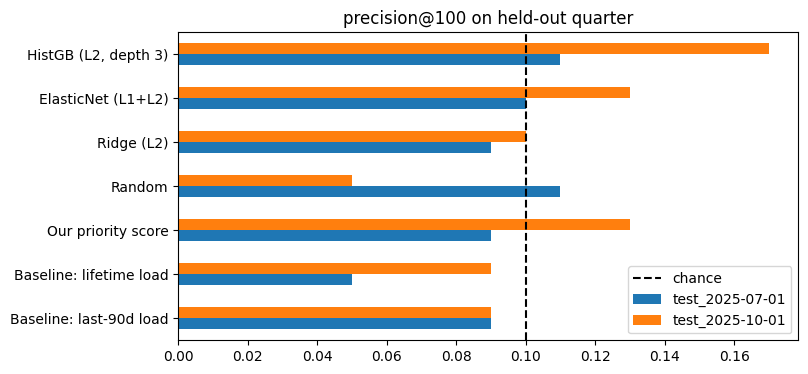

In [3]:
m = pd.DataFrame({k: {n: x['precision_at_100'] for n, x in v.items() if not n.startswith('_')} for k, v in val.items()})
m.plot.barh(figsize=(8,4)); plt.axvline(.10, c='k', ls='--', label='chance'); plt.legend(); plt.title('precision@100 on held-out quarter'); plt.show()